# Problema 5 — Segmentação de Clientes Utilizando k-Means

Um distribuidor atacadista atende, ao mesmo tempo, clientes muito diferentes entre si: o restaurante que compra hortifrúti e congelados em alto giro, o pequeno mercado de bairro que se abastece de mercearia, laticínios e produtos de limpeza, entre outros. Tratar todos eles com a mesma política comercial é, na prática, desperdiçar margem e capacidade logística.

A segmentação de clientes tem aplicações diretas no planejamento de rotas e estoques, na definição de campanhas promocionais dirigidas, na concessão de limites de crédito e na identificação de clientes atípicos, que merecem atendimento dedicado. No Brasil, o crescimento do modelo de atacarejo e a importância dos distribuidores regionais no abastecimento do interior do Nordeste tornam o problema especialmente concreto para a nossa realidade.

Este projeto tem uma característica que o distingue dos anteriores: não existe um rótulo a ser previsto. Ninguém classificou previamente os clientes em “perfil restaurante” ou “perfil varejo”; se esses grupos existem, eles precisam emergir da própria estrutura dos gastos. É o domínio do aprendizado não supervisionado.

Neste projeto, você é convidado a identificar perfis de consumo de clientes de um distribuidor atacadista por meio do algoritmo de agrupamento k-Means.

O projeto utiliza o arquivo `Wholesale customers data.csv` do dataset [Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers). O dataset foi doado por Margarida G. M. S. Cardoso (ISCTE-IUL, Lisboa, Portugal) em 2014 e reúne 440 clientes de um distribuidor atacadista português. Para cada cliente são registrados os gastos anuais, em unidades monetárias, em seis categorias de produto — **Fresh** (frescos), **Milk** (laticínios), **Grocery** (mercearia), **Frozen** (congelados), **Detergents_Paper** (detergentes e papel) e **Delicassen** (delicatessen) — além de dois atributos categóricos: **Channel**, indicando se o cliente pertence ao canal **Horeca** (hotéis, restaurantes e cafés, 298 clientes) ou **Retail** (varejo, 142 clientes), e **Region**, indicando sua localização (Lisboa, Porto ou outras regiões).

**Observação:** os atributos `Channel` e `Region` **não** devem ser utilizados no agrupamento. Eles serão reservados para a validação externa da tarefa 5. O agrupamento deve basear-se exclusivamente nas seis categorias de gasto.

Realize as seguintes tarefas utilizando o dataset fornecido:

## 1. Preparação dos dados

Carregue o dataset e separe `Channel` e `Region` do restante. Para cada uma das seis categorias de gasto, calcule média, mediana, desvio padrão e valores extremos, e construa um boxplot ou histograma. Você observará distribuições fortemente assimétricas à direita, com poucos clientes de gasto muito elevado — em `Fresh`, por exemplo, os valores vão de dezenas a mais de cem mil unidades monetárias. Aplique então a transformação logarítmica $x' = \log(1 + x)$ e, em seguida, padronize os atributos por Z-score.

Justifique as duas etapas separadamente: (a) por que a transformação logarítmica é recomendável diante da assimetria e da presença de outliers, e (b) por que a padronização é determinante para o k-Means, relacionando sua resposta ao uso da distância euclidiana na atribuição dos pontos aos centróides. Calcule também a matriz de correlação entre as seis categorias e comente o par `Grocery`–`Detergents_Paper`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 

# chanel vem junto ao X
# data (as pandas dataframes) 
X = wholesale_customers.data.features 
y = wholesale_customers.data.targets 

y = y.copy()
y['Channel'] = X['Channel']

X = X.drop('Channel', axis=1)
  
# metadata 
print(wholesale_customers.metadata) 
  
# variable information 
print(wholesale_customers.variables) 


{'uci_id': 292, 'name': 'Wholesale customers', 'repository_url': 'https://archive.ics.uci.edu/dataset/292/wholesale+customers', 'data_url': 'https://archive.ics.uci.edu/static/public/292/data.csv', 'abstract': 'The data set refers to clients of a wholesale distributor. It includes the annual spending in monetary units (m.u.) on diverse product categories', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 440, 'num_features': 7, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['Region'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2013, 'last_updated': 'Mon Feb 05 2024', 'dataset_doi': '10.24432/C5030X', 'creators': ['Margarida Cardoso'], 'intro_paper': None, 'additional_info': {'summary': None, 'purpose': None, 'funded_by': None, 'instances_represent': None, 'recommended_data_splits': None, 'sensitive_data': None, 'preprocessing_description':

In [4]:
X

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...
435,29703,12051,16027,13135,182,2204
436,39228,1431,764,4510,93,2346
437,14531,15488,30243,437,14841,1867
438,10290,1981,2232,1038,168,2125


In [5]:
y

,Region,Channel
0,3,2
1,3,2
2,3,2
3,3,1
4,3,2
...,...,...
435,3,1
436,3,1
437,3,2
438,3,1


Feita a separação de Region e Channel.

In [6]:
print("-"*50)
print("Média")
print("-"*50)
print(X.mean())  
print("-"*50)
print("Mediana")
print("-"*50)
print(X.median())        # mediana
print("-"*50)
print("Desvio Padrão")
print("-"*50)
print(X.std())           # desvio padrao (amostral)
print("-"*50)
print("Mínimos")
print(X.min())
print("-"*50)
print("Máximos")
print(X.max())

--------------------------------------------------
Média
--------------------------------------------------
Fresh               12000.297727
Milk                 5796.265909
Grocery              7951.277273
Frozen               3071.931818
Detergents_Paper     2881.493182
Delicassen           1524.870455
dtype: float64
--------------------------------------------------
Mediana
--------------------------------------------------
Fresh               8504.0
Milk                3627.0
Grocery             4755.5
Frozen              1526.0
Detergents_Paper     816.5
Delicassen           965.5
dtype: float64
--------------------------------------------------
Desvio Padrão
--------------------------------------------------
Fresh               12647.328865
Milk                 7380.377175
Grocery              9503.162829
Frozen               4854.673333
Detergents_Paper     4767.854448
Delicassen           2820.105937
dtype: float64
--------------------------------------------------
Mínimos
Fres

In [7]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

print("-"*50)
print("Deteção de Outliers")
print("-"*50)
lim_inf = Q1 - 1.5 * (Q3 - Q1)
lim_sup = Q3 + 1.5 * (Q3 - Q1)

outliers = (X < lim_inf) | (X > lim_sup)
print(outliers.sum())      # nº de outliers por atributo

--------------------------------------------------
Deteção de Outliers
--------------------------------------------------
Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicassen          27
dtype: int64


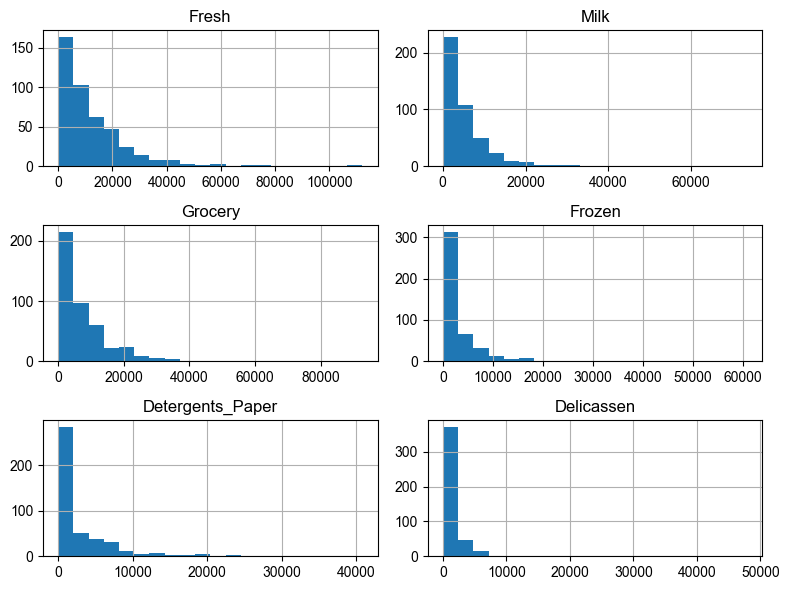

In [8]:
X.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

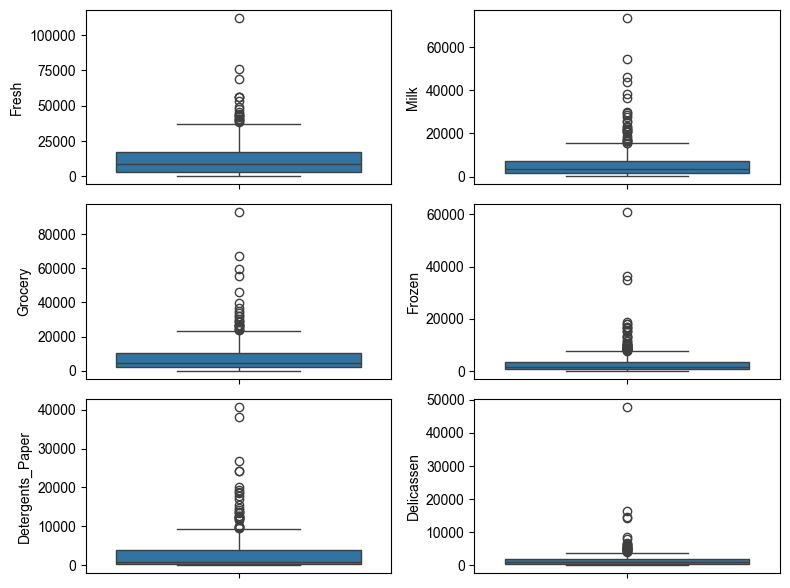

In [9]:
import seaborn as sns
plt.figure(figsize=(8, 6))
for idx in range(6):
    plt.subplot(3, 2, idx + 1)          # idx+1 -> 1,2,3,4 (subplot comeca em 1)
    col = X.columns[idx]
    sns.boxplot(data=X, y=col)

plt.tight_layout()
plt.show()

In [10]:
X_lnha = np.log1p(X)

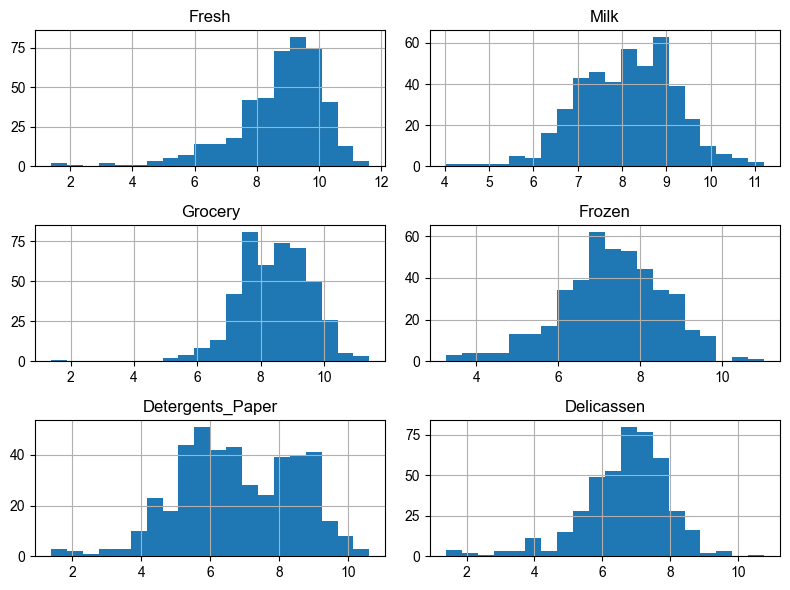

In [11]:
X_lnha.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_lnha = scaler.fit_transform(X_lnha)

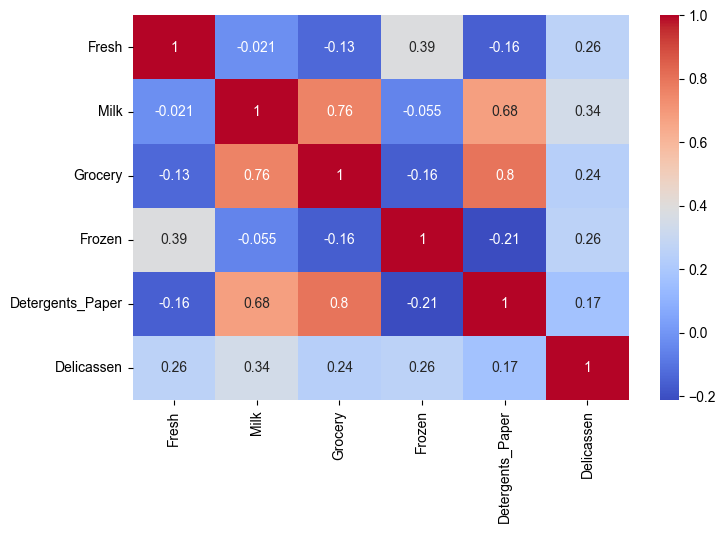

In [13]:
X_plot = pd.DataFrame(X_lnha, columns=X.columns, index=X.index)

corr = X_plot.corr() 
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

### Resposta — item 1

A transformação `log(1 + x)` comprime os gastos muito altos e reduz sua influência sobre as distâncias, o que é útil diante das distribuições assimétricas e dos clientes com gastos gigantes. 

Depois, o Z-score coloca cada atributo com média zero e desvio padrão um. Essa etapa é importante porque o k-Means usa distância euclidiana: sem padronização, categorias com maior diferença poderiam dominar a medida de distância.

No heatmap, `Grocery` e `Detergents_Paper` têm correlação de **0,80**. Clientes que gastam mais em grocery tendem também a gastar mais em detergentes e papel.

## 2. Ausência de divisão treino/teste

Diferentemente dos projetos anteriores, aqui não se separa um conjunto de teste. Explique por quê, contrastando o objetivo do aprendizado supervisionado (estimar o erro de generalização sobre rótulos conhecidos) com o do não supervisionado. Discuta, então, qual é a dificuldade central da validação em agrupamento: como afirmar que uma partição é “boa” sem dispor de um gabarito?

### Resposta — item 2

Aqui o objetivo é descobrir perfis entre os clientes disponíveis, e não prever um rótulo conhecido para medir o erro de classificação em um teste. Por isso, conforme a proposta da questão, o agrupamento usa a base inteira.

Sem um gabarito de segmentos, não existe uma medida direta de “percentual de clientes corretamente agrupados”. Avaliamos a coesão e a separação por índices como a silhueta, a interpretabilidade dos perfis e a relação posterior com Channel e Region. Esses critérios fornecem evidências, mas não provam uma única partição correta. Em outras aplicações não supervisionadas, avaliar estabilidade ou comportamento em novos dados também pode ser útil.

## 3. Escolha do número de grupos

Execute o k-Means para k variando de 2 a 10. Plote a inércia (soma dos quadrados intra-cluster) em função de k e aplique o método do cotovelo; em seguida, plote o coeficiente de silhueta médio em função de k. Escolha o valor de k justificando sua decisão à luz dos dois critérios e da interpretabilidade comercial dos grupos resultantes — um segmento só é útil se a área comercial souber o que fazer com ele. Responda: por que a inércia decresce monotonicamente com k e por que, portanto, ela não pode ser usada isoladamente como critério de escolha? O que ocorre no caso limite em que k é igual ao número de amostras?

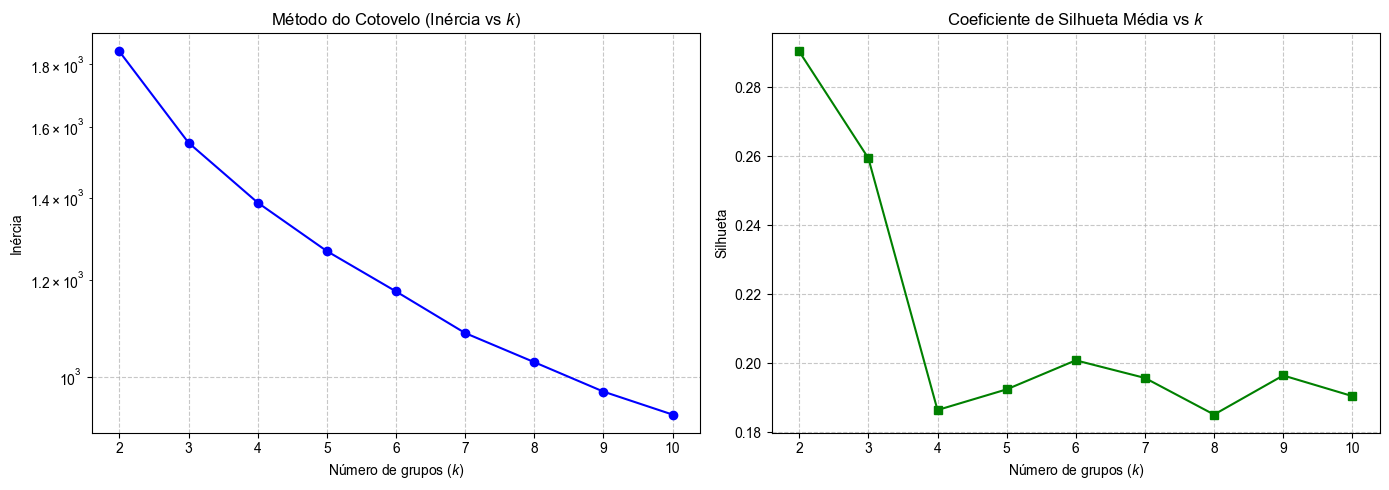

In [14]:
inercia = []
silhueta = []
k_valores = range(2, 11)

for k in k_valores:
    kmeans = KMeans(n_clusters=k, random_state=42, max_iter=100, tol=1e-3, n_init=10)
    kmeans.fit(X_lnha)
    
    inercia.append(kmeans.inertia_)
    silhueta.append(silhouette_score(X_lnha, kmeans.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_valores, inercia, marker='o', color='blue')
ax1.set_title('Método do Cotovelo (Inércia vs $k$)')
ax1.set_xlabel('Número de grupos ($k$)')
ax1.set_ylabel('Inércia')
ax1.set_yscale("log")
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(k_valores, silhueta, marker='s', color='green')
ax2.set_title('Coeficiente de Silhueta Média vs $k$')
ax2.set_xlabel('Número de grupos ($k$)')
ax2.set_ylabel('Silhueta')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [15]:
k_escolhido = 2
modelo_my = KMeans(n_clusters=k_escolhido, random_state=42, max_iter=100, tol=1e-3, n_init=10)
rotulos_my = modelo_my.fit_predict(X_lnha)

print(f"Inércia (KMeans):     {modelo_my.inertia_:.4f}")
print(f"Iterações (melhor execução): {modelo_my.n_iter_}")

print(f"Silhueta média: {silhouette_score(X_lnha, rotulos_my):.4f}")
print("\nCentróides padronizados:")
display(pd.DataFrame(modelo_my.cluster_centers_, columns=X.columns))

Inércia (KMeans):     1844.0880
Iterações (melhor execução): 6
Silhueta média: 0.2903

Centróides padronizados:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,-0.290849,0.805288,0.855436,-0.344690,0.882606,0.199024
1,0.219006,-0.606372,-0.644133,0.259547,-0.664591,-0.149863


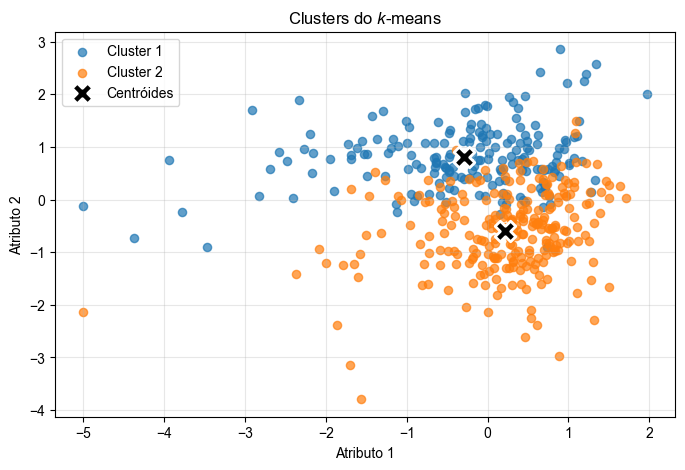

In [16]:
for c in range(k_escolhido):
    mask = rotulos_my == c
    plt.scatter(X_lnha[mask, 0], X_lnha[mask, 1], s=35, alpha=0.7, label=f"Cluster {c+1}")
plt.scatter(modelo_my.cluster_centers_[:, 0], modelo_my.cluster_centers_[:, 1],
            marker="X", s=220, c="black", edgecolors="white", linewidths=2,
            label="Centróides", zorder=5)
plt.title("Clusters do $k$-means")
plt.xlabel("Atributo 1")
plt.ylabel("Atributo 2")
plt.legend()
plt.grid(alpha=0.3)

### Resposta — item 3

Escolhi **k = 2**, pois apresentou o maior coeficiente de silhueta entre os valores avaliados, aproximadamente 0,26. Quanto maior a silhueta, melhor a combinação de coesão dos grupos e separação entre eles. 

A inércia continua diminuindo com o aumento de k, mas o gráfico não apresenta um cotovelo. Com dois grupos, a interpretação comercial também é simples: um perfil seria o varejo e outro seria algo como restaurantes ou hoteis.

Quando k é igual ao número de amostras, cada cliente pode ser seu próprio centróide e a inércia chega a zero, se usássemos o menor valor de inercia k sempre seria = a quantidade de amostra, ou se fosse um valor pequeno de inercia o k sempre seria grande ao ponto de cair no overfit, e quando o cotovelo não está tão presente, ou não existe no grafico da inercia, a silhueta serve como um otimo complemento para a escolha de k.

## 4. Inicialização e convergência

O k-Means converge para um mínimo local, e não necessariamente global. Execute o algoritmo dez vezes com `init='random'` e `n_init=1`, usando sementes distintas, e registre a inércia final de cada execução. Repita o procedimento com `init='k-means++'`. Compare a dispersão dos resultados nos dois casos e explique qual problema a inicialização k-means++ busca mitigar e de que forma.

,Random,k-means++
0,1844.064069,1844.127031
1,1844.064069,1844.064069
2,1844.064069,1844.064069
3,1844.127031,1844.064069
4,1844.064069,1844.127031
5,1844.064069,1844.064069
6,1844.127031,1844.127031
7,1844.127031,1844.127031
8,1844.064069,1844.064069
9,1844.064069,1844.064069


--- Dispersão dos Resultados ---
Random Init* Desvio Padrão: 0.0289 | Amplitude: 0.0630
K-Means++- Desvio Padrão: 0.0308 | Amplitude: 0.0630


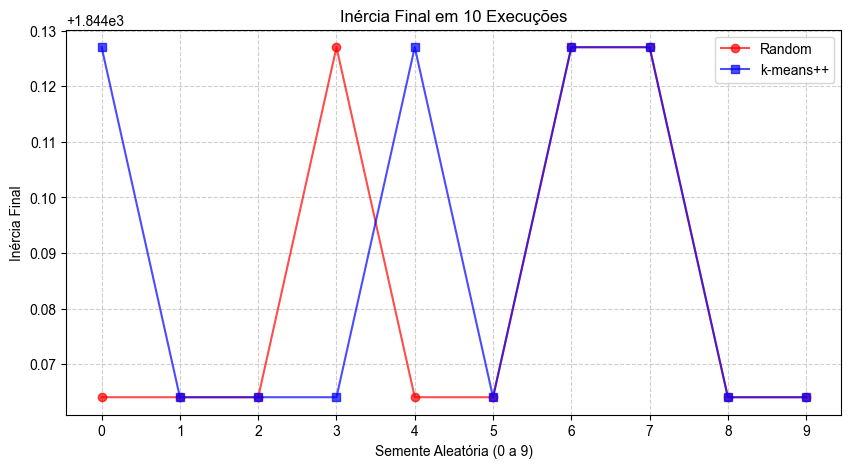

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_bichao = k_escolhido 

inercias_random = []
inercias_kmeansMM = []

for semente in range(10):
    kmeans_random = KMeans(n_clusters=k_bichao, init='random', n_init=1, random_state=semente)
    kmeans_random.fit(X_lnha)
    inercias_random.append(kmeans_random.inertia_)
    
    kmeans_pp = KMeans(n_clusters=k_bichao, init='k-means++', n_init=1, random_state=semente)
    kmeans_pp.fit(X_lnha)
    inercias_kmeansMM.append(kmeans_pp.inertia_)

df_comparacao = pd.DataFrame({
    'Random': inercias_random,
    'k-means++': inercias_kmeansMM
})
display(df_comparacao)

print("--- Dispersão dos Resultados ---")
print(f"Random Init* Desvio Padrão: {np.std(inercias_random):.4f} | Amplitude: {np.max(inercias_random) - np.min(inercias_random):.4f}")
print(f"K-Means++- Desvio Padrão: {np.std(inercias_kmeansMM):.4f} | Amplitude: {np.max(inercias_kmeansMM) - np.min(inercias_kmeansMM):.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range(10), inercias_random, marker='o', linestyle='-', label="Random", color='red', alpha=0.7)
plt.plot(range(10), inercias_kmeansMM, marker='s', linestyle='-', label="k-means++", color='blue', alpha=0.7)
plt.title('Inércia Final em 10 Execuções')
plt.xlabel('Semente Aleatória (0 a 9)')
plt.ylabel('Inércia Final')
plt.xticks(range(10))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Resposta — item 4

Nas dez sementes avaliadas com **k = 2**, a inicialização aleatória teve desvio padrão da inércia de **0,0289** e amplitude de **0,0630**. Com k-means++, esses valores foram **0,0308** e **0,0630**. As duas inicializações produziram resultados muito próximos; neste experimento, o k-means++ não reduziu a dispersão.

O k-means++ procura evitar centróides iniciais muito próximos: após escolher o primeiro, seleciona os próximos favorecendo pontos mais distantes dos centróides já escolhidos, com probabilidades proporcionais ao quadrado dessas distâncias. Isso tende a melhorar o ponto de partida, mas não garante encontrar o mínimo global nem obter menor dispersão em todo experimento.


## 5. Interpretação e validação dos grupos

Com o k escolhido, recupere os centróides, reverta-os para a escala original de gasto (desfazendo a padronização e a transformação logarítmica) e apresente-os em uma tabela e em um gráfico de barras agrupadas por categoria. Atribua a cada agrupamento um nome descritivo de natureza comercial, baseado nas categorias em que ele se destaca.

Em seguida, realize uma validação externa: construa tabelas de contingência cruzando o agrupamento de cada cliente com `Channel` e com `Region`, e calcule o índice Rand ajustado (Adjusted Rand Index) entre a partição obtida e a variável `Channel`. Responda: o algoritmo, sem jamais ter visto o canal de venda, foi capaz de reconstruí-lo? Qual conjunto de categorias de produto mais separa Horeca de Retail? E a região geográfica — ela se reflete nos agrupamentos?

Por fim, projete os dados em duas dimensões por PCA, colorindo os pontos por agrupamento, e discuta duas limitações do k-Means evidenciadas nesse gráfico: a tendência a formar grupos de geometria esférica e de tamanhos semelhantes e a sensibilidade a outliers.

Centróides na escala original (Gastos representativos em m.u.):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Perfil varejo,4045.36,8028.26,11990.6,954.06,4018.44,1019.79
Perfil restaurante/hotéis,8556.14,1748.51,2267.9,2069.32,285.27,649.28


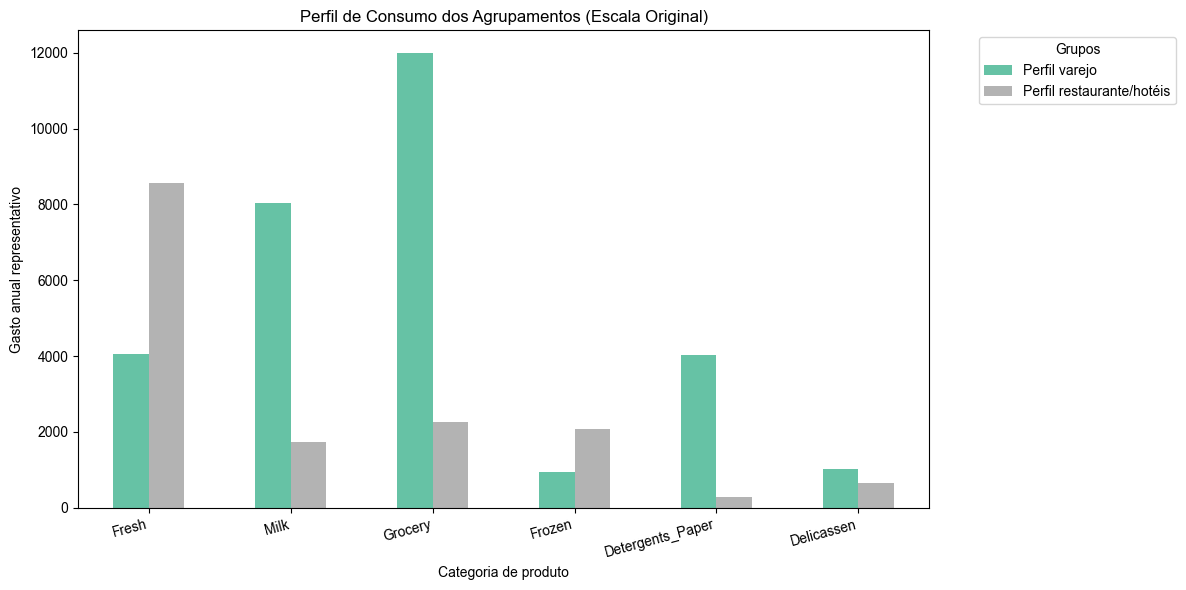

In [18]:
from sklearn.decomposition import PCA

centroides_padronizados = modelo_my.cluster_centers_
centroides_log = scaler.inverse_transform(centroides_padronizados)
centroides_originais = np.expm1(centroides_log)
# Média geométrica de (1 + gasto), menos 1; não é a média aritmética.

df_centroides = pd.DataFrame(centroides_originais, columns=X.columns)

grupo_mercearia = df_centroides['Detergents_Paper'].idxmax()
nomes_grupos = [
    'Perfil varejo' if g == grupo_mercearia
    else 'Perfil restaurante/hotéis'
    for g in range(k_escolhido)
]
df_centroides.index = nomes_grupos

print("Centróides na escala original (Gastos representativos em m.u.):")
display(df_centroides.round(2))

df_centroides.T.plot(kind='bar', figsize=(12, 6), colormap='Set2')
plt.title('Perfil de Consumo dos Agrupamentos (Escala Original)')
plt.ylabel('Gasto anual representativo')
plt.xlabel('Categoria de produto')
plt.xticks(rotation=15, ha='right')
plt.legend(title='Grupos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Resposta — item 5: perfis comerciais

Os dois perfis foram nomeados a partir dos centróides na escala original de gasto:

- **Perfil varejo (grupo 0, 188 clientes):** apresenta gastos representativos maiores em Grocery (**11.990,60**), Milk (**8.028,26**) e Detergents_Paper (**4.018,44**). Sugere oportunidades de ofertas conjuntas e reposição nessas categorias.
- **Perfil restaurante/hotéis (grupo 1, 252 clientes):** apresenta gastos representativos maiores em Fresh (**8.556,14**) e Frozen (**2.069,32**) em comparação ao outro grupo. Sugere ofertas voltadas ao abastecimento de produtos frescos e congelados.

A inversão do log e da padronização fornece gastos representativos dos centróides. Eles não são médias aritméticas dos gastos originais: correspondem à média geométrica de (1 + gasto), menos 1.


In [19]:
rotulos = modelo_my.labels_

print("\nTabela de Contingência: Grupos x Channel (1=Horeca, 2=Retail)")
tabela_channel = pd.crosstab(index=rotulos, columns=y['Channel'], rownames=['Grupo (k-Means)'], colnames=['Channel'])
display(tabela_channel)

print("\nTabela de Contingência: Grupos x Region (1=Lisboa, 2=Porto, 3=Outras)")
tabela_region = pd.crosstab(index=rotulos, columns=y['Region'], rownames=['Grupo (k-Means)'], colnames=['Region'])
display(tabela_region)

ari_channel = adjusted_rand_score(y['Channel'], rotulos)
print(f"\nAdjusted Rand Index (Grupos vs Channel): {ari_channel:.4f}")


Tabela de Contingência: Grupos x Channel (1=Horeca, 2=Retail)


Channel,1,2
Grupo (k-Means),,
0,54,134
1,244,8



Tabela de Contingência: Grupos x Region (1=Lisboa, 2=Porto, 3=Outras)


Region,1,2,3
Grupo (k-Means),,,
0,29,19,140
1,48,28,176



Adjusted Rand Index (Grupos vs Channel): 0.5135


### Resposta — item 5: canal de venda e região

O ARI foi de **0,5135**, indicando uma correspondência entre os agrupamentos e o canal de venda. O perfil varejo reúne **134 clientes Retail e 54 Horeca**, enquanto o perfil restaurante/hotéis reúne **244 clientes Horeca e 8 Retail**. Portanto, mesmo sem usar Channel no treinamento, o algoritmo recuperou parte da estrutura dos canais, mas não os reconstruiu perfeitamente.

Grocery, Milk e Detergents_Paper caracterizam o perfil mais associado a Retail. Fresh e Frozen apresentam valores maiores no perfil predominantemente Horeca. A combinação de gastos em mercearia, laticínios e limpeza ajuda, assim, a distinguir os canais.

A região não aparece como uma divisão clara: o grupo 0 tem **29 clientes de Lisboa, 19 do Porto e 140 de outras regiões**; o grupo 1 tem **48 de Lisboa, 28 do Porto e 176 de outras regiões**. As outras regiões representam aproximadamente **74,47%** e **69,84%** dos respectivos grupos, proporções próximas dos **71,82%** da base. As tabelas sugerem pouca diferenciação regional, como se não tivesse tanta diferença entre o perfil de lisboa e porto por exemplo, para esse problema.


In [20]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_lnha)

pesos_pca = pd.DataFrame(
    pca.components_, 
    columns=X.columns, 
    index=['Componente Principal 1', 'Componente Principal 2']
)

print("Pesos PCA")
display(pesos_pca)

Pesos PCA


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Componente Principal 1,-0.105250,0.542329,0.571472,-0.137910,0.550642,0.214469
Componente Principal 2,0.590359,0.132911,-0.005751,0.589778,-0.070822,0.530022


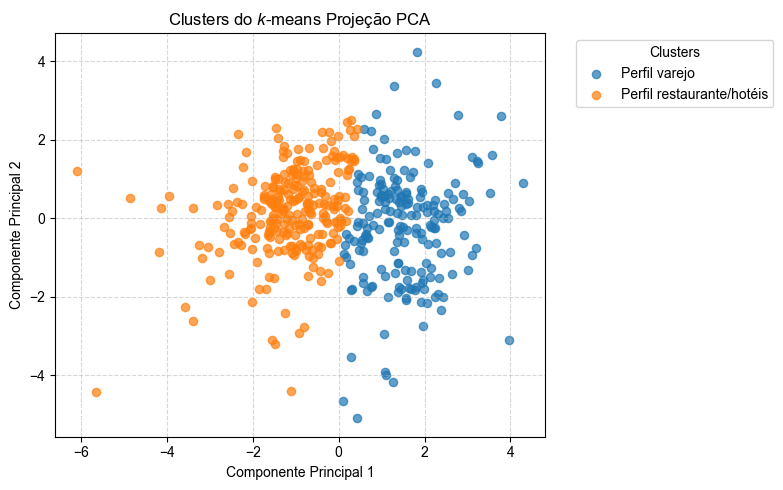

In [21]:
for c in range(k_escolhido):
    mask = rotulos_my == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=35, alpha=0.7, label=nomes_grupos[c])

plt.title("Clusters do $k$-means Projeção PCA")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Resposta — item 5: PCA e limitações do k-Means

Os dois grupos apresentam sobreposição, principalmente perto do centro, e existem pontos afastados das regiões de maior densidade.

O k-Means favorece grupos compactos, esféricos e com dispersões comparáveis. Nuvens alongadas, sobrepostas ou com densidades muito diferentes podem não ser bem representadas por um único centroide. Um dos casos em que ele é menos preciso é em dados com geometria não convexa, como os em formato de banana ou de lua. Como a sua separação tende a agrupar os dados em áreas com formato de circunferência, o algoritmo não consegue identificar corretamente clusters com geometrias mais complexas.

Os pontos afastados também ilustram a sensibilidade a outliers, pois o algoritmo utiliza distâncias para as suas otimizações, e esses pontos extremos podem deslocar os centroides de forma artificial.
